In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from keras.models import Sequential
from keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler # good for financial data
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import streamlit as st

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

/Users/tomcuel/.venvs/global_env/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
def fetch_data(symbol):
    stock = yf.Ticker(symbol)
    data = stock.history(period="5y")
    return data

data = fetch_data("AAPL")
data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-10-13 00:00:00-04:00,137.761419,137.917467,135.771654,137.439545,78762700,0.0,0.0
2021-10-14 00:00:00-04:00,138.610019,140.336430,138.024790,140.219376,69907100,0.0,0.0
2021-10-15 00:00:00-04:00,140.229142,141.331301,139.975536,141.272781,67940300,0.0,0.0
2021-10-18 00:00:00-04:00,139.916987,143.223494,139.634136,142.940643,85589200,0.0,0.0
2021-10-19 00:00:00-04:00,143.389292,145.496097,142.940630,145.096191,76378900,0.0,0.0


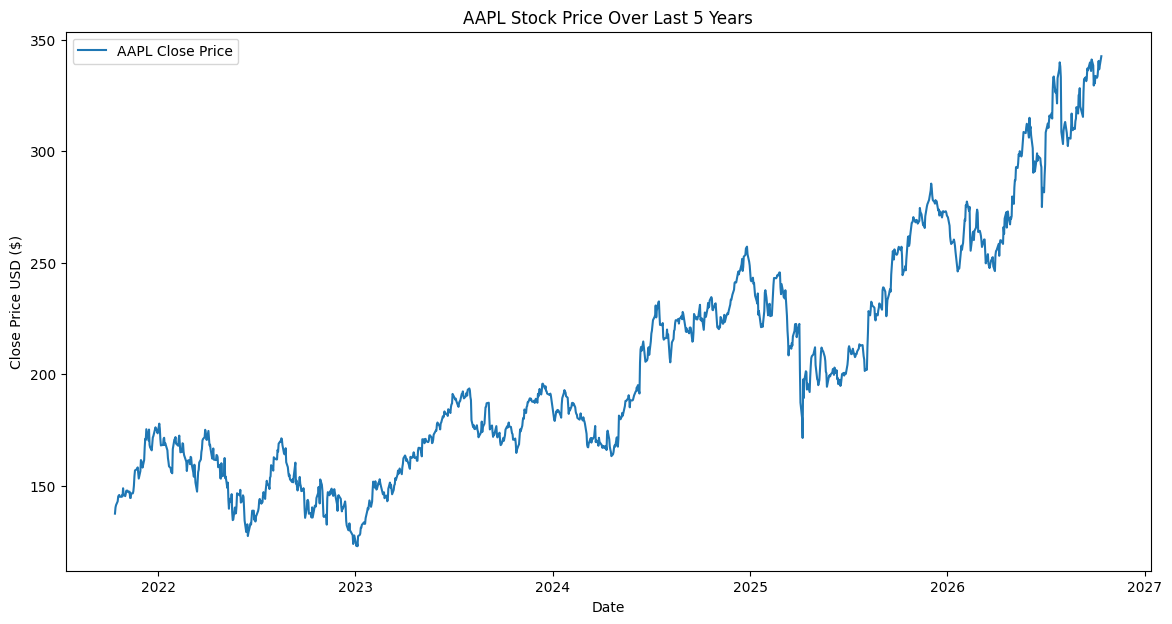

In [3]:
plt.figure(figsize=(14, 7))
plt.plot(data['Close'], label='AAPL Close Price')
plt.title('AAPL Stock Price Over Last 5 Years')
plt.xlabel('Date')
plt.ylabel('Close Price USD ($)')
plt.legend()
plt.show()

In [4]:
def preprocess_data(df):
    df['SMA_50'] = df['Close'].rolling(window=50).mean()
    df['EMA_50'] = df['Close'].ewm(span=20, adjust=False).mean()
    df['Daily_Return'] = df['Close'].pct_change()
    df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

    delta = df['Close'].diff(1)
    gain = (delta.where(delta >0,0)).rolling(window=14).mean()
    loss = (-delta.where(delta<0,0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI_14'] = 100 -(100 / (1 + rs))
    df['Middle_Band'] = df['Close'].rolling(window=20).mean()
    df['Upper_Band'] = df['Middle_Band'] + (df['Close'].rolling(window=20).std() * 2)
    df['Lower_Band'] = df['Middle_Band'] - (df['Close'].rolling(window=20).std() * 2)
    df['Momentum'] = df['Close'] - df['Close'].shift(4)
    df['Volatility'] = df['Close'].rolling(window=21).std()

    df.dropna(inplace=True)
    return df

data = preprocess_data(data)
data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA_50,EMA_50,Daily_Return,Log_Return,RSI_14,Middle_Band,Upper_Band,Lower_Band,Momentum,Volatility
Date,,,,,,,,,,,,,,,,,
2021-12-22 00:00:00-05:00,169.024537,171.779105,168.155190,171.564209,92135300,0.0,0.0,154.416258,165.412343,0.015319,0.015203,62.885005,165.635067,178.547647,152.722486,3.301544,6.528765
2021-12-23 00:00:00-05:00,171.769317,172.746111,171.202774,172.189331,68356600,0.0,0.0,155.111254,166.057771,0.003644,0.003637,66.108849,166.335426,179.064111,153.606741,5.020706,6.453304
2021-12-27 00:00:00-05:00,172.980566,176.233294,172.961040,176.145386,74919600,0.0,0.0,155.829774,167.018496,0.022975,0.022715,66.534487,167.484138,179.326421,155.641856,10.334503,6.562183
2021-12-28 00:00:00-05:00,175.979307,177.122155,174.387128,175.129486,79144300,0.0,0.0,156.506908,167.790971,-0.005767,-0.005784,59.995048,168.414533,179.532083,157.296983,6.153778,6.007522
2021-12-29 00:00:00-05:00,175.168565,176.438400,174.006177,175.217407,62348900,0.0,0.0,157.152444,168.498251,0.000502,0.000502,55.848730,169.102196,180.110455,158.093937,3.653198,5.617717


In [5]:
def normalize_data(df):
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(df[['Close']])
    return scaled_data, scaler

print(data['Close'][:5])  # Display first 5 rows of preprocessed data
scaled_data, scaler = normalize_data(data)
scaled_data[:5]  # Display first 5 rows of scaled data

Date
2021-12-22 00:00:00-05:00    171.564209
2021-12-23 00:00:00-05:00    172.189331
2021-12-27 00:00:00-05:00    176.145386
2021-12-28 00:00:00-05:00    175.129486
2021-12-29 00:00:00-05:00    175.217407
Name: Close, dtype: float64


array([[0.22182504],
       [0.22467029],
       [0.24267631],
       [0.23805243],
       [0.2384526 ]])

In [6]:
def prepare_data(scaled_data, time_steps=60):
    X, y = [], []
    for i in range(time_steps, len(scaled_data)):
        X.append(scaled_data[i - time_steps:i])
        y.append(scaled_data[i,0])
    return np.array(X), np.array(y)

X, y = prepare_data(scaled_data)
X.shape, y.shape

((1146, 60, 1), (1146,))

In [7]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

In [8]:
def build_model(input_shape):
    model = Sequential([
        LSTM(50, return_sequences=True, input_shape=input_shape),
        LSTM(50, return_sequences=False),
        Dense(25),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss = 'mean_squared_error')
    return model

model = build_model((X.shape[1], X.shape[2]))
model.summary()

/Users/tomcuel/.venvs/global_env/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.fit(x_train, y_train, batch_size=32, epochs=30)
loss = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss: {loss}')

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 0.0153
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0016
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0012
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0012
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0011
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0011
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0010
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 9.5598e-04
Epoch 9/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 9.1798e-04
Epoch 10/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 9.0779e-04
Epoch 11/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 8.8310e-04
Epoch 12/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 9.3322e-04
Epoch 13/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 8.1975e-04
Epoch 14/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 8.1049e-04
Epoch 15/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 2

In [10]:
# In-sample predictions (on training + test set)
y_train_pred = model.predict(x_train, verbose=0)
y_train_pred = scaler.inverse_transform(y_train_pred)[:,0]
y_test_pred = model.predict(x_test, verbose=0)
y_test_pred = scaler.inverse_transform(y_test_pred)[:,0]


# Align predictions with dates
prediction_dates = data.index[60:]  # first 60 points are used as input
in_sample_df_train = pd.DataFrame({
    'Date': prediction_dates[:len(y_train_pred)],
    'Predicted': y_train_pred,
    'Actual': data['Close'][60:60+len(y_train_pred)]
})
in_sample_df_test = pd.DataFrame({
    'Date': prediction_dates[len(y_train_pred):],
    'Predicted': y_test_pred,
    'Actual': data['Close'][60+len(y_train_pred):]
})

In [11]:
# Future predictions (10 days)
future_seq = y_test[-60:].reshape(60, 1)
future_preds = []

for day in range(10):
    X_input = future_seq.reshape(1, 60, 1)
    pred = model.predict(X_input, verbose=0)[0][0]
    future_preds.append(pred)
    future_seq = np.vstack([future_seq[1:], [[pred]]])

future_preds = scaler.inverse_transform(np.array(future_preds).reshape(-1, 1))[:,0]
future_dates = pd.date_range(start=pd.Timestamp.now() + pd.DateOffset(1), periods=10)

In [12]:
# Plot everything together
fig = go.Figure()
fig.update_layout(width=1400, height=600)

# Historical Close Price
fig.add_trace(go.Scatter(
    x=data.index,
    y=data['Close'],
    mode='lines',
    name='Historical Close',
    line=dict(color='lightgray')
))
# In-sample Predictions for the Training Set
fig.add_trace(go.Scatter(
    x=in_sample_df_train['Date'],
    y=in_sample_df_train['Predicted'],
    mode='lines',
    name='Model Predictions (Train)',
    line=dict(color='blue')
))
# In-sample Predictions for the Test Set
fig.add_trace(go.Scatter(
    x=in_sample_df_test['Date'],
    y=in_sample_df_test['Predicted'],
    mode='lines',
    name='Model Predictions (Test)',
    line=dict(color='orange')
))
# Future Forecasts
fig.add_trace(go.Scatter(
    x=future_dates,
    y=future_preds,
    mode='lines+markers',
    name='Future Forecast',
    line=dict(color='red', dash='dot')
))
fig.update_layout(
    title='Stock Price Prediction: Historical + In-sample + Future Forecast',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    template='plotly_dark'
)

In [13]:
# Plot everything together
fig = go.Figure()
fig.update_layout(width=1400, height=600)

# Historical Close Price
fig.add_trace(go.Scatter(
    x=data.index[-500:],
    y=data['Close'][-500:],
    mode='lines',
    name='Historical Close',
    line=dict(color='lightgray')
))
# In-sample Predictions (test there since the number of points is smaller)
fig.add_trace(go.Scatter(
    x=in_sample_df_test['Date'][-500:],
    y=in_sample_df_test['Predicted'][-500:],
    mode='lines',
    name='Model Predictions',
    line=dict(color='blue')
))
# Future Forecasts
fig.add_trace(go.Scatter(
    x=future_dates,
    y=future_preds,
    mode='lines+markers',
    name='Future Forecast',
    line=dict(color='red', dash='dot')
))
fig.update_layout(
    title='Stock Price Prediction: Historical + In-sample + Future Forecast',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    template='plotly_dark'
)